# Regression V1 — XGBoost Baseline

서울 아파트 실거래가를 예측하는 Regression V1 최종 Baseline 노트북.

## 목표
- 시간 순서를 보존한 Train / Validation / Test 분할
- XGBoost Baseline 성능 검증
- 가격대·월별 오차 및 Feature Importance 해석
- 높은 R²에 대한 Leakage / Robustness Audit 수행
- 검증 완료 후 V1 모델·전처리기·성능·예측 결과 저장

## 데이터 분할
- **Train:** 2021-07 ~ 2025-06
- **Validation:** 2025-07 ~ 2025-12
- **Test:** 2026-01 ~ 2026-06

> Test는 모델 선택 및 튜닝에 사용하지 않고 최종 평가에만 사용한다.


In [7]:
# ============================================================
# 1. 라이브러리 및 데이터 로드
# ============================================================

from pathlib import Path
import json
import time

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder
from xgboost import XGBRegressor


plt.rcParams["font.family"] = "Malgun Gothic"
plt.rcParams["axes.unicode_minus"] = False


PROJECT_DIR = Path.cwd().parents[3]

DATA_DIR = PROJECT_DIR / "data"
V2_DATA_DIR = DATA_DIR / "v2_5year_seoul"
PROCESSED_DIR = V2_DATA_DIR / "processed"
FINAL_PATH = PROCESSED_DIR / "df_final_v1.parquet"

df = pd.read_parquet(FINAL_PATH)

print("shape:", df.shape)
print(
    "기간:",
    df["거래월일자"].min(),
    "~",
    df["거래월일자"].max(),
)


shape: (234302, 124)
기간: 2021-07-01 00:00:00 ~ 2026-06-01 00:00:00


In [8]:
# ============================================================
# 2. Target 생성 및 시간 기준 분할
# ============================================================

df["log_price"] = np.log1p(df["거래금액"])
TARGET = "log_price"

train_mask = df["거래월일자"] < "2025-07-01"

valid_mask = (
    (df["거래월일자"] >= "2025-07-01")
    & (df["거래월일자"] < "2026-01-01")
)

test_mask = df["거래월일자"] >= "2026-01-01"

train_df = df.loc[train_mask].copy()
valid_df = df.loc[valid_mask].copy()
test_df = df.loc[test_mask].copy()

for name, data in [
    ("Train", train_df),
    ("Valid", valid_df),
    ("Test", test_df),
]:
    print(
        f"{name:5} | "
        f"{data['거래월일자'].min().date()} "
        f"~ {data['거래월일자'].max().date()} "
        f"| {len(data):,}건 "
        f"({len(data) / len(df):.1%})"
    )


Train | 2021-07-01 ~ 2025-06-01 | 160,945건 (68.7%)
Valid | 2025-07-01 ~ 2025-12-01 | 33,788건 (14.4%)
Test  | 2026-01-01 ~ 2026-06-01 | 39,569건 (16.9%)


In [9]:
# ============================================================
# 3. V1 Baseline Feature 구성
# ============================================================

# 모델에서 제외할 Target / 사후정보 / 식별성 컬럼
exclude_cols = [
    "transaction_id",

    # Target / Target 파생
    "거래금액",
    "log_price",
    "평당가",
    "log_평당가",

    # 거래 이후 정보
    "등기일자",
    "해제여부",
    "해제사유발생일",
    "매도자",
    "매수자",

    # 주소 / 식별 정보
    "도로명",
    "지번",
    "아파트동명",

    # 코드형 숫자
    "법정동시군구코드",
    "법정동읍면동코드",
    "법정동지번코드",
    "법정동본번코드",
    "법정동부번코드",
    "도로명시군구코드",
    "도로명코드",
    "도로명일련번호코드",
    "도로명지상지하코드",
    "도로명건물본번호코드",
    "도로명건물부번호코드",
    "시군구코드",
]

# 중복 숫자형 Feature
drop_numeric_cols = [
    "계약년도",
    "계약월",
    "계약일",
    "건축년도",
    "거래연월",
    "거래년도",
    "거래월",
    "분기",

    # 거리 단위는 m로 통일
    "응급의료기관거리_km",
    "대규모점포거리_km",
    "주요일자리거리_km",
]

baseline_cat_cols = [
    "거래유형",
    "토지임대부아파트여부",
    "최근접노선",
    "최근접응급의료기관분류",
    "최근접대규모점포업태",
    "최근접주요일자리",
    "전세피처출처_전월",
    "전세피처출처_과거3개월",
    "전세피처출처_과거6개월",
]

baseline_numeric_cols = [
    col
    for col in df.select_dtypes(include="number").columns
    if col not in exclude_cols
    and col not in drop_numeric_cols
]

baseline_feature_cols = baseline_numeric_cols + baseline_cat_cols

print("숫자형 Feature:", len(baseline_numeric_cols))
print("범주형 Feature:", len(baseline_cat_cols))
print("전체 Feature  :", len(baseline_feature_cols))


숫자형 Feature: 59
범주형 Feature: 9
전체 Feature  : 68


In [10]:
# ============================================================
# 4. X / y 구성 + 기본 누수·결측 검증
# ============================================================

X_train = train_df[baseline_feature_cols].copy()
X_valid = valid_df[baseline_feature_cols].copy()
X_test = test_df[baseline_feature_cols].copy()

y_train = train_df[TARGET].copy()
y_valid = valid_df[TARGET].copy()
y_test = test_df[TARGET].copy()


# 명백한 Target / 사후정보가 Feature에 들어갔는지 확인
forbidden_feature_cols = {
    "거래금액",
    "log_price",
    "평당가",
    "log_평당가",
    "등기일자",
    "해제여부",
    "해제사유발생일",
    "매도자",
    "매수자",
}

leaked_cols = sorted(
    forbidden_feature_cols.intersection(baseline_feature_cols)
)

assert not leaked_cols, f"누수 의심 Feature 발견: {leaked_cols}"

# 시간 분할 경계 검증
assert (
    train_df["거래월일자"].max()
    < valid_df["거래월일자"].min()
)
assert (
    valid_df["거래월일자"].max()
    < test_df["거래월일자"].min()
)

# 숫자형 dtype 통일
for X in [X_train, X_valid, X_test]:
    X[baseline_numeric_cols] = (
        X[baseline_numeric_cols]
        .astype("float64")
    )

summary = pd.DataFrame({
    "Split": ["Train", "Validation", "Test"],
    "Rows": [len(X_train), len(X_valid), len(X_test)],
    "Numeric Missing": [
        X_train[baseline_numeric_cols].isna().sum().sum(),
        X_valid[baseline_numeric_cols].isna().sum().sum(),
        X_test[baseline_numeric_cols].isna().sum().sum(),
    ],
    "Categorical Missing": [
        X_train[baseline_cat_cols].isna().sum().sum(),
        X_valid[baseline_cat_cols].isna().sum().sum(),
        X_test[baseline_cat_cols].isna().sum().sum(),
    ],
    "Target Missing": [
        y_train.isna().sum(),
        y_valid.isna().sum(),
        y_test.isna().sum(),
    ],
})

display(summary)
print("명백한 Target/사후정보 누수 Feature: 없음")


,Split,Rows,Numeric Missing,Categorical Missing,Target Missing
0,Train,160945,159764,13623,0
1,Validation,33788,2,0,0
2,Test,39569,0,0,0


명백한 Target/사후정보 누수 Feature: 없음


## Feature 설계 원칙

Regression V1은 현재 거래의 `거래금액` 및 직접 파생값을 입력 Feature에서 제거한다.  
지역 매매가격·전월세·금리·정책 관련 Feature는 **해당 거래시점에서 이용 가능한 과거 정보**를 사용하는 것을 전제로 한다.

특히 높은 중요도를 보일 수 있는 지역 가격 Feature는 현재월 가격이 아니라 전월/과거 구간 집계값이어야 한다.
이 부분은 뒤의 **Market Price Lag Ablation**에서 추가로 의존도를 점검한다.


In [11]:
# ============================================================
# 5. 전처리 Pipeline
# ============================================================

categorical_pipeline = Pipeline([
    (
        "imputer",
        SimpleImputer(
            strategy="constant",
            fill_value="미상",
        ),
    ),
    (
        "onehot",
        OneHotEncoder(
            handle_unknown="ignore",
            sparse_output=True,
        ),
    ),
])

preprocessor = ColumnTransformer(
    transformers=[
        (
            "numeric",
            "passthrough",
            baseline_numeric_cols,
        ),
        (
            "categorical",
            categorical_pipeline,
            baseline_cat_cols,
        ),
    ],
)

X_train_processed = preprocessor.fit_transform(X_train)
X_valid_processed = preprocessor.transform(X_valid)
X_test_processed = preprocessor.transform(X_test)

print("Train:", X_train_processed.shape)
print("Valid:", X_valid_processed.shape)
print("Test :", X_test_processed.shape)


Train: (160945, 118)
Valid: (33788, 118)
Test : (39569, 118)


In [12]:
# ============================================================
# 6. XGBoost Baseline 학습
# ============================================================

EPOCHS = 10_000
EARLY_STOPPING_ROUNDS = 100
PRINT_EVERY = 100

baseline_model = XGBRegressor(
    objective="reg:squarederror",
    n_estimators=EPOCHS,
    learning_rate=0.05,
    max_depth=6,
    subsample=0.8,
    colsample_bytree=0.8,
    reg_lambda=1.0,
    tree_method="hist",
    eval_metric="rmse",
    early_stopping_rounds=EARLY_STOPPING_ROUNDS,
    random_state=42,
    n_jobs=-1,
)

start_time = time.time()

baseline_model.fit(
    X_train_processed,
    y_train,
    eval_set=[(X_valid_processed, y_valid)],
    verbose=PRINT_EVERY,
)

elapsed_time = time.time() - start_time

print("\n===== Baseline 학습 완료 =====")
print(f"Best Epoch          : {baseline_model.best_iteration:,}")
print(f"Best Validation RMSE: {baseline_model.best_score:.6f}")
print(f"학습 시간           : {elapsed_time:.1f}초")


[0]	validation_0-rmse:0.61293
[100]	validation_0-rmse:0.16849
[200]	validation_0-rmse:0.15307
[300]	validation_0-rmse:0.14595
[400]	validation_0-rmse:0.14130
[500]	validation_0-rmse:0.13836
[600]	validation_0-rmse:0.13611
[700]	validation_0-rmse:0.13426
[800]	validation_0-rmse:0.13275
[900]	validation_0-rmse:0.13153
[1000]	validation_0-rmse:0.13056
[1100]	validation_0-rmse:0.12963
[1200]	validation_0-rmse:0.12887
[1300]	validation_0-rmse:0.12827
[1400]	validation_0-rmse:0.12790
[1500]	validation_0-rmse:0.12727
[1600]	validation_0-rmse:0.12678
[1700]	validation_0-rmse:0.12644
[1800]	validation_0-rmse:0.12606
[1900]	validation_0-rmse:0.12574
[2000]	validation_0-rmse:0.12560
[2100]	validation_0-rmse:0.12532
[2200]	validation_0-rmse:0.12509
[2300]	validation_0-rmse:0.12483
[2400]	validation_0-rmse:0.12459
[2500]	validation_0-rmse:0.12449
[2600]	validation_0-rmse:0.12436
[2700]	validation_0-rmse:0.12424
[2800]	validation_0-rmse:0.12411
[2900]	validation_0-rmse:0.12401
[3000]	validation_0-rm

In [13]:
# ============================================================
# 7. Validation 성능 평가
# ============================================================

valid_pred_log = baseline_model.predict(X_valid_processed)
valid_pred_price = np.expm1(valid_pred_log)
valid_actual_price = np.expm1(y_valid)

# Log Scale
log_rmse = np.sqrt(mean_squared_error(y_valid, valid_pred_log))
log_mae = mean_absolute_error(y_valid, valid_pred_log)
log_r2 = r2_score(y_valid, valid_pred_log)

# Original Price Scale
price_rmse = np.sqrt(
    mean_squared_error(valid_actual_price, valid_pred_price)
)
price_mae = mean_absolute_error(
    valid_actual_price,
    valid_pred_price,
)
price_r2 = r2_score(
    valid_actual_price,
    valid_pred_price,
)

# Error Rate
valid_ape = (
    np.abs(valid_actual_price - valid_pred_price)
    / valid_actual_price
    * 100
)

mape = valid_ape.mean()
median_ape = np.median(valid_ape)

validation_metrics = pd.Series({
    "Log RMSE": log_rmse,
    "Log MAE": log_mae,
    "Log R²": log_r2,
    "Price RMSE": price_rmse,
    "Price MAE": price_mae,
    "Price R²": price_r2,
    "MAPE (%)": mape,
    "Median APE (%)": median_ape,
    "오차 5% 이내 (%)": (valid_ape <= 5).mean() * 100,
    "오차 10% 이내 (%)": (valid_ape <= 10).mean() * 100,
    "오차 20% 이내 (%)": (valid_ape <= 20).mean() * 100,
})

display(
    validation_metrics
    .to_frame("Validation")
)


,Validation
Log RMSE,0.122688
Log MAE,0.090987
Log R²,0.962702
Price RMSE,22138.341344
Price MAE,12232.652760
Price R²,0.935638
MAPE (%),8.746788
Median APE (%),6.634928
오차 5% 이내 (%),39.330532
오차 10% 이내 (%),66.354919


In [14]:
# ============================================================
# 8. 가격대별 Validation 성능 및 Bias
# ============================================================

valid_result = pd.DataFrame({
    "거래월일자": valid_df["거래월일자"].to_numpy(),
    "실제가격": np.asarray(valid_actual_price),
    "예측가격": np.asarray(valid_pred_price),
})

valid_result["절대오차"] = np.abs(
    valid_result["실제가격"]
    - valid_result["예측가격"]
)

valid_result["오차율"] = (
    valid_result["절대오차"]
    / valid_result["실제가격"]
    * 100
)

valid_result["예측오차"] = (
    valid_result["예측가격"]
    - valid_result["실제가격"]
)

valid_result["예측비율"] = (
    valid_result["예측가격"]
    / valid_result["실제가격"]
)

valid_result["가격대"] = pd.cut(
    valid_result["실제가격"],
    bins=[
        0,
        50_000,
        100_000,
        150_000,
        200_000,
        np.inf,
    ],
    labels=[
        "5억 이하",
        "5~10억",
        "10~15억",
        "15~20억",
        "20억 초과",
    ],
)

price_group_summary = (
    valid_result
    .groupby("가격대", observed=True)
    .agg(
        거래건수=("실제가격", "size"),
        MAE_만원=("절대오차", "mean"),
        MAPE=("오차율", "mean"),
        중앙오차율=("오차율", "median"),
        실제가격_평균=("실제가격", "mean"),
        예측가격_평균=("예측가격", "mean"),
        평균예측오차=("예측오차", "mean"),
        평균예측비율=("예측비율", "mean"),
    )
)

display(price_group_summary)


,거래건수,MAE_만원,MAPE,중앙오차율,실제가격_평균,예측가격_평균,평균예측오차,평균예측비율
가격대,,,,,,,,
5억 이하,3827,3245.599086,9.595865,6.445817,34556.828848,36230.242188,1673.414116,1.049076
5~10억,12999,4738.947282,6.369681,4.607275,74984.615509,74388.273438,-596.338374,0.994657
10~15억,8790,10209.720398,8.239930,6.662597,122352.344482,114970.960938,-7381.385182,0.941670
15~20억,4501,19575.816289,11.342223,10.555659,171553.048656,153961.343750,-17591.705397,0.898380
20억 초과,3671,43977.171511,14.310350,14.159842,305449.960229,264617.125000,-40832.832750,0.867088


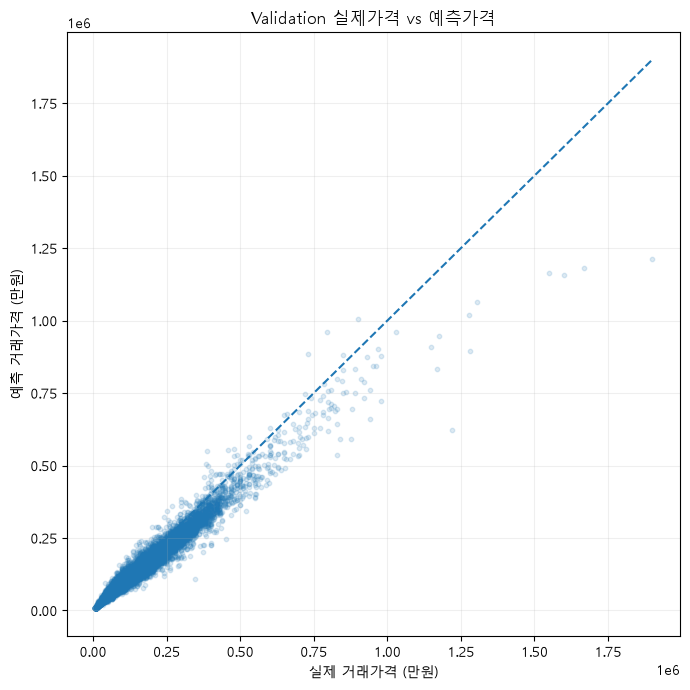

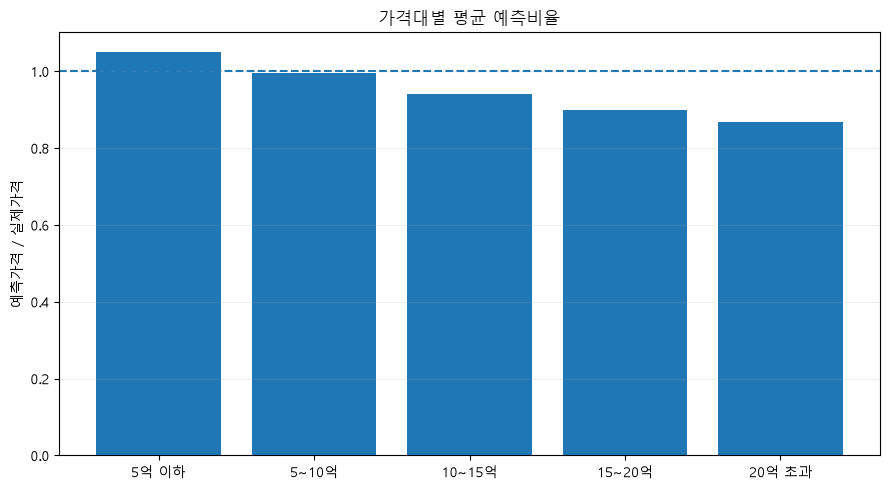

In [15]:
# ============================================================
# 9. Validation 시각화 — 실제 vs 예측 / 가격대별 Bias
# ============================================================

fig, ax = plt.subplots(figsize=(7, 7))

ax.scatter(
    valid_result["실제가격"],
    valid_result["예측가격"],
    alpha=0.15,
    s=10,
)

min_price = min(
    valid_result["실제가격"].min(),
    valid_result["예측가격"].min(),
)
max_price = max(
    valid_result["실제가격"].max(),
    valid_result["예측가격"].max(),
)

ax.plot(
    [min_price, max_price],
    [min_price, max_price],
    linestyle="--",
    linewidth=1.5,
)

ax.set_title("Validation 실제가격 vs 예측가격")
ax.set_xlabel("실제 거래가격 (만원)")
ax.set_ylabel("예측 거래가격 (만원)")
ax.grid(alpha=0.2)

plt.tight_layout()
plt.show()


bias_plot = price_group_summary.reset_index()

fig, ax = plt.subplots(figsize=(9, 5))

ax.bar(
    bias_plot["가격대"],
    bias_plot["평균예측비율"],
)
ax.axhline(1.0, linestyle="--", linewidth=1.5)

ax.set_title("가격대별 평균 예측비율")
ax.set_ylabel("예측가격 / 실제가격")
ax.set_xlabel("")
ax.grid(axis="y", alpha=0.2)

plt.tight_layout()
plt.show()


### Validation 해석

- 전체 성능만으로 판단하지 않고 **가격대별 MAPE와 예측비율**을 함께 확인한다.
- `평균예측비율 < 1`이면 실제보다 낮게 예측하는 경향, `> 1`이면 높게 예측하는 경향을 의미한다.
- 초고가 구간에서 과소예측이 커진다면 개별 단지 프리미엄·재건축 기대·희소성 등 현재 V1 Feature로 충분히 설명되지 않는 요인이 남아 있다는 의미다.


,Original_Feature,Importance
0,전세피처출처_과거3개월,0.164636
1,구_전월_중위평당가,0.148043
2,최근접주요일자리,0.110942
3,전용면적,0.095812
4,전세평당가_과거6개월,0.092675
5,전세피처출처_과거6개월,0.087510
6,구_전월_중위가격,0.038963
7,최근접노선,0.036524
8,최근접응급의료기관분류,0.020570
9,구_과거3개월_중위가격,0.019539


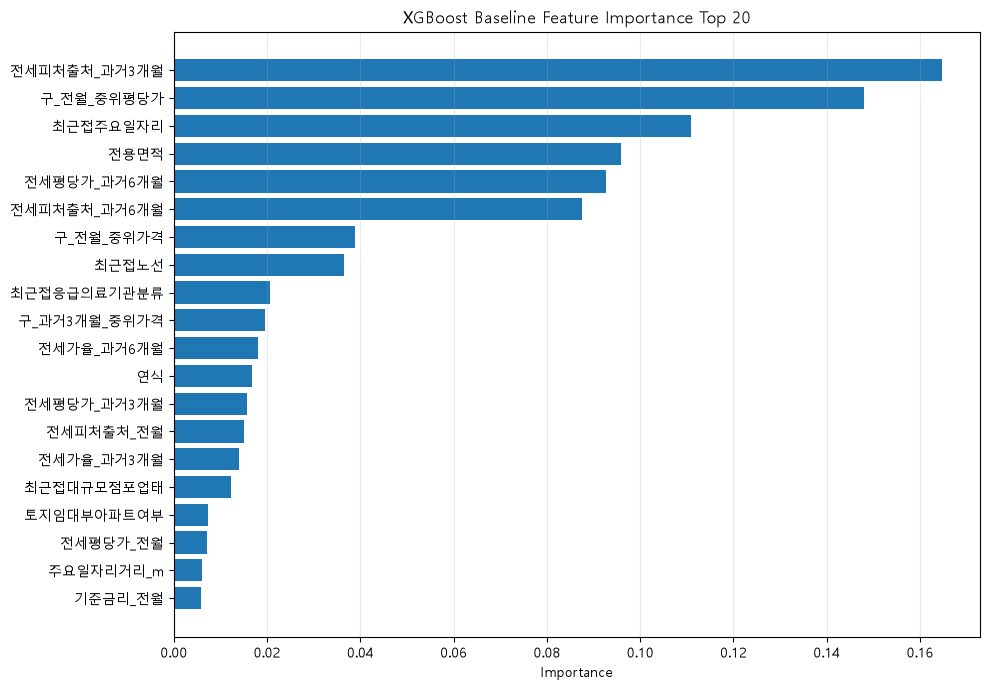

In [16]:
# ============================================================
# 10. Feature Importance
# ============================================================

processed_feature_names = preprocessor.get_feature_names_out()

feature_importance = pd.DataFrame({
    "Feature": processed_feature_names,
    "Importance": baseline_model.feature_importances_,
})

feature_importance["Feature"] = (
    feature_importance["Feature"]
    .str.replace("numeric__", "", regex=False)
    .str.replace("categorical__", "", regex=False)
)


def get_original_feature(feature_name):
    for col in baseline_cat_cols:
        if feature_name.startswith(f"{col}_"):
            return col
    return feature_name


grouped_importance = (
    feature_importance
    .assign(
        Original_Feature=lambda x: (
            x["Feature"].apply(get_original_feature)
        )
    )
    .groupby("Original_Feature", as_index=False)["Importance"]
    .sum()
    .sort_values("Importance", ascending=False)
    .reset_index(drop=True)
)

display(grouped_importance.head(30))

top_importance = (
    grouped_importance
    .head(20)
    .sort_values("Importance")
)

fig, ax = plt.subplots(figsize=(10, 7))

ax.barh(
    top_importance["Original_Feature"],
    top_importance["Importance"],
)

ax.set_title("XGBoost Baseline Feature Importance Top 20")
ax.set_xlabel("Importance")
ax.grid(axis="x", alpha=0.25)

plt.tight_layout()
plt.show()


### Feature Importance 해석

서울 아파트 가격 예측에서는 일반적으로 **최근 지역 가격 수준, 전용면적, 전월세시장 정보, 연식, 입지 접근성**과 같은 Feature가 핵심 설명력을 가질 수 있다.

다만 XGBoost의 기본 Feature Importance는 **인과관계가 아니라 모델이 분할에 활용한 정도**를 나타낸다.
특정 가격 Lag Feature의 중요도가 높더라도 그것만으로 누수라고 판단할 수 없으며,
해당 Feature를 제거했을 때 성능이 얼마나 변하는지 Ablation으로 확인해야 한다.

또한 `전세피처출처_*`가 높은 중요도를 보인다면 단순 결측 표시뿐 아니라
단지/법정동 단위에서 전세 데이터가 얼마나 축적되었는지, 즉 거래 활성도나 데이터 가용성을 간접적으로 반영했을 가능성이 있다.


,거래월일자,거래건수,실제가격_중위값,예측가격_중위값,실제가격_평균,예측가격_평균,MAE_만원,MAPE,중위가격_예측비율
0,2025-07-01,4149,94000.0,93513.281250,127796.373584,122609.984375,9889.427418,6.961551,0.994822
1,2025-08-01,4277,88000.0,87246.812500,105568.029460,102564.289062,7919.905868,7.345686,0.991441
2,2025-09-01,8665,108500.0,102716.296875,121156.829429,111900.750000,11754.784442,8.389201,0.946694
3,2025-10-01,8533,107000.0,102950.093750,126497.501113,116454.398438,13676.763048,9.166356,0.962150
4,2025-11-01,3390,99500.0,94830.789062,130716.004130,118003.804688,16189.664890,10.364207,0.953073
5,2025-12-01,4774,89500.0,85242.789062,109305.029535,98423.945312,13609.176676,10.304128,0.952433


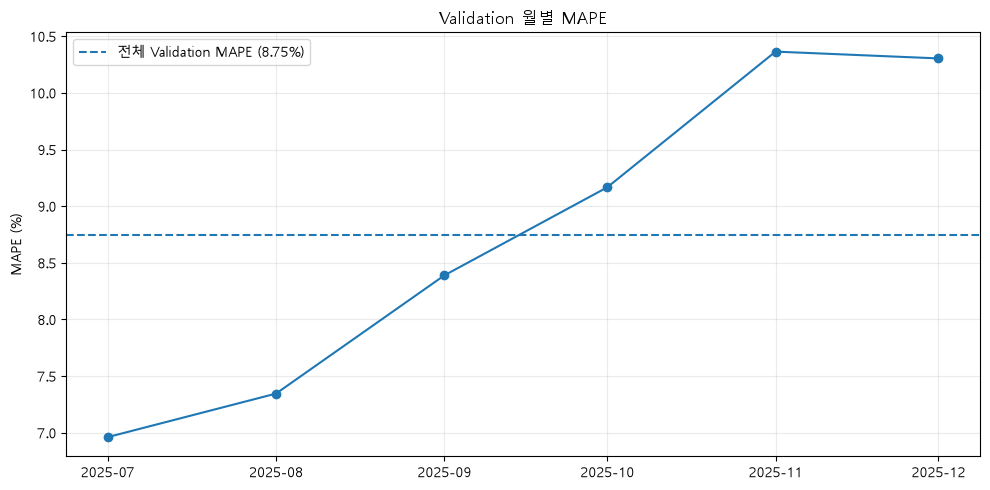

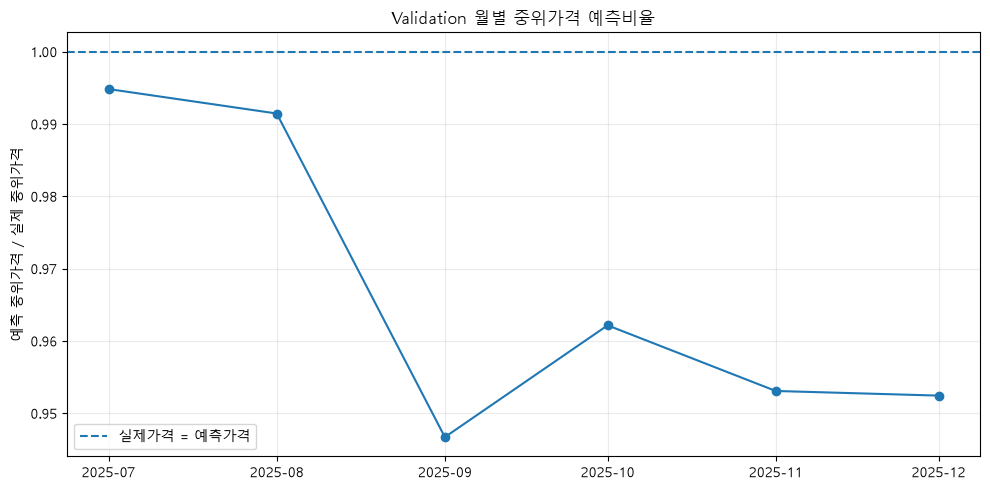

In [17]:
# ============================================================
# 11. Validation 월별 성능 및 시간 경과 Bias
# ============================================================

monthly_valid = (
    valid_result
    .groupby("거래월일자")
    .agg(
        거래건수=("실제가격", "size"),
        실제가격_중위값=("실제가격", "median"),
        예측가격_중위값=("예측가격", "median"),
        실제가격_평균=("실제가격", "mean"),
        예측가격_평균=("예측가격", "mean"),
        MAE_만원=("절대오차", "mean"),
        MAPE=("오차율", "mean"),
    )
    .reset_index()
)

monthly_valid["중위가격_예측비율"] = (
    monthly_valid["예측가격_중위값"]
    / monthly_valid["실제가격_중위값"]
)

display(monthly_valid)


fig, ax = plt.subplots(figsize=(10, 5))

ax.plot(
    monthly_valid["거래월일자"],
    monthly_valid["MAPE"],
    marker="o",
)

ax.axhline(
    mape,
    linestyle="--",
    label=f"전체 Validation MAPE ({mape:.2f}%)",
)

ax.set_title("Validation 월별 MAPE")
ax.set_ylabel("MAPE (%)")
ax.set_xlabel("")
ax.legend()
ax.grid(alpha=0.25)

plt.tight_layout()
plt.show()


fig, ax = plt.subplots(figsize=(10, 5))

ax.plot(
    monthly_valid["거래월일자"],
    monthly_valid["중위가격_예측비율"],
    marker="o",
)

ax.axhline(
    1.0,
    linestyle="--",
    label="실제가격 = 예측가격",
)

ax.set_title("Validation 월별 중위가격 예측비율")
ax.set_ylabel("예측 중위가격 / 실제 중위가격")
ax.set_xlabel("")
ax.legend()
ax.grid(alpha=0.25)

plt.tight_layout()
plt.show()


### 시간 안정성 해석

월별 MAPE와 예측비율을 함께 보면 모델이 Validation 기간 동안 시장 변화에 얼마나 안정적으로 대응하는지 확인할 수 있다.

- 학습 종료 시점에서 멀어질수록 MAPE가 지속적으로 커지면 **시간 경과에 따른 성능 저하** 가능성이 있다.
- 중위가격 예측비율이 1 아래로 내려가면 해당 월 시장가격 상승을 모델이 충분히 따라가지 못한 것으로 볼 수 있다.
- 평균가격 기반 Bias가 중위가격보다 더 크다면 일부 초고가 거래의 과소예측 영향이 섞였을 가능성이 있다.


In [18]:
# ============================================================
# 12. Validation 기준 최적 boosting round 확정
# ============================================================

BEST_ESTIMATORS = baseline_model.best_iteration + 1

print(f"최종 Estimators: {BEST_ESTIMATORS:,}")


최종 Estimators: 4,352


In [19]:
# ============================================================
# 13. Train + Validation 통합 후 최종 재학습
# ============================================================

train_valid_df = pd.concat(
    [train_df, valid_df],
    axis=0,
).copy()

X_train_valid = (
    train_valid_df[baseline_feature_cols]
    .copy()
)

y_train_valid = (
    train_valid_df[TARGET]
    .copy()
)

X_train_valid[baseline_numeric_cols] = (
    X_train_valid[baseline_numeric_cols]
    .astype("float64")
)

final_preprocessor = clone(preprocessor)

X_train_valid_processed = (
    final_preprocessor
    .fit_transform(X_train_valid)
)

X_test_final_processed = (
    final_preprocessor
    .transform(X_test)
)

final_baseline_model = XGBRegressor(
    objective="reg:squarederror",
    n_estimators=BEST_ESTIMATORS,
    learning_rate=0.05,
    max_depth=6,
    subsample=0.8,
    colsample_bytree=0.8,
    reg_lambda=1.0,
    tree_method="hist",
    eval_metric="rmse",
    random_state=42,
    n_jobs=-1,
)

start_time = time.time()

final_baseline_model.fit(
    X_train_valid_processed,
    y_train_valid,
    verbose=False,
)

elapsed_time = time.time() - start_time

print("===== 최종 Baseline 학습 완료 =====")
print(f"학습 데이터 : {len(X_train_valid):,}건")
print(f"Feature 수  : {X_train_valid_processed.shape[1]:,}개")
print(f"Estimators  : {BEST_ESTIMATORS:,}")
print(f"학습 시간   : {elapsed_time:.1f}초")


===== 최종 Baseline 학습 완료 =====
학습 데이터 : 194,733건
Feature 수  : 118개
Estimators  : 4,352
학습 시간   : 87.9초


In [20]:
# ============================================================
# 14. Test 최종 성능 + Validation 비교
# ============================================================

test_pred_log = final_baseline_model.predict(
    X_test_final_processed
)

test_pred_price = np.expm1(test_pred_log)
test_actual_price = np.expm1(y_test)

# Log Scale
test_log_rmse = np.sqrt(
    mean_squared_error(y_test, test_pred_log)
)
test_log_mae = mean_absolute_error(
    y_test, test_pred_log
)
test_log_r2 = r2_score(
    y_test, test_pred_log
)

# Original Price Scale
test_price_rmse = np.sqrt(
    mean_squared_error(
        test_actual_price,
        test_pred_price,
    )
)
test_price_mae = mean_absolute_error(
    test_actual_price,
    test_pred_price,
)
test_price_r2 = r2_score(
    test_actual_price,
    test_pred_price,
)

# Error Rate
test_ape = (
    np.abs(test_actual_price - test_pred_price)
    / test_actual_price
    * 100
)

test_mape = test_ape.mean()
test_median_ape = np.median(test_ape)

performance_compare = pd.DataFrame({
    "Validation": [
        log_rmse,
        log_mae,
        log_r2,
        price_rmse,
        price_mae,
        price_r2,
        mape,
        median_ape,
    ],
    "Test": [
        test_log_rmse,
        test_log_mae,
        test_log_r2,
        test_price_rmse,
        test_price_mae,
        test_price_r2,
        test_mape,
        test_median_ape,
    ],
}, index=[
    "Log RMSE",
    "Log MAE",
    "Log R²",
    "Price RMSE",
    "Price MAE",
    "Price R²",
    "MAPE (%)",
    "Median APE (%)",
])

display(performance_compare)

print("\n===== Test 오차 구간 =====")
print(f"오차 5% 이내  : {(test_ape <= 5).mean() * 100:.1f}%")
print(f"오차 10% 이내 : {(test_ape <= 10).mean() * 100:.1f}%")
print(f"오차 20% 이내 : {(test_ape <= 20).mean() * 100:.1f}%")


,Validation,Test
Log RMSE,0.122688,0.127445
Log MAE,0.090987,0.096160
Log R²,0.962702,0.961862
Price RMSE,22138.341344,18901.045530
Price MAE,12232.652760,10838.104506
Price R²,0.935638,0.958535
MAPE (%),8.746788,9.334730
Median APE (%),6.634928,7.407520



===== Test 오차 구간 =====
오차 5% 이내  : 35.2%
오차 10% 이내 : 62.9%
오차 20% 이내 : 91.4%


## Leakage / Robustness Audit

Test R²가 매우 높기 때문에 모델을 저장하기 전에 두 가지 추가 검증을 수행한다.

### Audit 1 — Market Price Lag Ablation
구/서울 단위의 과거 매매가격 Lag Feature를 제거하고 동일한 XGBoost 설정으로 재학습한다.

- 제거 후에도 높은 성능이 유지되면 다른 주택·입지·전월세 Feature에도 충분한 설명력이 있다는 의미다.
- 성능이 크게 하락하면 V1이 최근 지역가격 수준에 강하게 의존하고 있다는 의미다.
- **성능 하락 자체는 누수를 뜻하지 않는다.** 해당 Feature가 예측시점 이전 정보라면 정상적인 강한 Feature일 수 있다.

### Audit 2 — Unseen Complex
Train + Validation에서 한 번도 등장하지 않은 단지의 Test 거래만 별도로 평가한다.

- Seen 성능은 기존 단지의 미래 거래가격 예측 능력
- Unseen 성능은 학습에서 보지 못한 단지에 대한 일반화 능력

서비스 범위가 기존 서울 아파트의 다음 거래가격 예측이라면 Seen 단지 성능도 정상적인 평가 대상이다.


In [21]:
# ============================================================
# 15. Audit 1 — Market Price Lag Ablation
# ============================================================

market_price_lag_cols = [
    col
    for col in baseline_feature_cols
    if (
        ("전세" not in col)
        and (
            "중위가격" in col
            or "중위평당가" in col
            or "평균가격" in col
        )
        and (
            "전월" in col
            or "과거3개월" in col
            or "과거6개월" in col
        )
    )
]

ablation_feature_cols = [
    col
    for col in baseline_feature_cols
    if col not in market_price_lag_cols
]

ablation_numeric_cols = [
    col
    for col in baseline_numeric_cols
    if col in ablation_feature_cols
]

ablation_cat_cols = [
    col
    for col in baseline_cat_cols
    if col in ablation_feature_cols
]

print("===== Market Price Lag Ablation =====")
print("기존 Feature :", len(baseline_feature_cols))
print("제거 Feature :", len(market_price_lag_cols))
print("잔여 Feature :", len(ablation_feature_cols))

print("\n제거 대상:")
for col in market_price_lag_cols:
    print("-", col)

if not market_price_lag_cols:
    raise ValueError(
        "제거할 과거 매매가격 Lag Feature가 발견되지 않았습니다. "
        "컬럼명을 확인하세요."
    )


===== Market Price Lag Ablation =====
기존 Feature : 68
제거 Feature : 7
잔여 Feature : 61

제거 대상:
- 구_전월_중위가격
- 구_전월_중위평당가
- 구_과거3개월_중위가격
- 구_과거6개월_중위가격
- 서울_전월_중위가격
- 서울_과거3개월_중위가격
- 서울_과거6개월_중위가격


In [22]:
# ============================================================
# 16. Ablation 재학습 및 성능 비교
# ============================================================

ablation_preprocessor = ColumnTransformer(
    transformers=[
        (
            "numeric",
            "passthrough",
            ablation_numeric_cols,
        ),
        (
            "categorical",
            clone(categorical_pipeline),
            ablation_cat_cols,
        ),
    ],
)

X_train_valid_ablation = (
    train_valid_df[ablation_feature_cols]
    .copy()
)

X_test_ablation = (
    test_df[ablation_feature_cols]
    .copy()
)

X_train_valid_ablation[ablation_numeric_cols] = (
    X_train_valid_ablation[ablation_numeric_cols]
    .astype("float64")
)

X_test_ablation[ablation_numeric_cols] = (
    X_test_ablation[ablation_numeric_cols]
    .astype("float64")
)

X_train_valid_ablation_processed = (
    ablation_preprocessor
    .fit_transform(X_train_valid_ablation)
)

X_test_ablation_processed = (
    ablation_preprocessor
    .transform(X_test_ablation)
)

ablation_model = clone(final_baseline_model)

ablation_model.fit(
    X_train_valid_ablation_processed,
    y_train_valid,
    verbose=False,
)

ablation_pred_log = ablation_model.predict(
    X_test_ablation_processed
)

ablation_pred_price = np.expm1(
    ablation_pred_log
)

actual_price_array = np.asarray(
    test_actual_price
)

ablation_r2 = r2_score(
    actual_price_array,
    ablation_pred_price,
)

ablation_rmse = np.sqrt(
    mean_squared_error(
        actual_price_array,
        ablation_pred_price,
    )
)

ablation_mae = mean_absolute_error(
    actual_price_array,
    ablation_pred_price,
)

ablation_mape = (
    np.abs(
        actual_price_array
        - ablation_pred_price
    )
    / actual_price_array
    * 100
).mean()

ablation_compare = pd.DataFrame({
    "모델": [
        "Full V1",
        "Market Price Lag 제거",
    ],
    "R2": [
        test_price_r2,
        ablation_r2,
    ],
    "RMSE_만원": [
        test_price_rmse,
        ablation_rmse,
    ],
    "MAE_만원": [
        test_price_mae,
        ablation_mae,
    ],
    "MAPE": [
        test_mape,
        ablation_mape,
    ],
})

display(ablation_compare)

print(f"R² 감소   : {test_price_r2 - ablation_r2:.4f}")
print(f"MAPE 증가 : {ablation_mape - test_mape:.2f}%p")


,모델,R2,RMSE_만원,MAE_만원,MAPE
0,Full V1,0.958535,18901.04553,10838.104506,9.334730
1,Market Price Lag 제거,0.961573,18195.30913,10600.919064,9.097872


R² 감소   : -0.0030
MAPE 증가 : -0.24%p


In [23]:
# ============================================================
# 17. Audit 2 — Seen / Unseen Complex 성능
# ============================================================

def make_complex_id(data):
    if (
        "단지일련번호" in data.columns
        and data["단지일련번호"].notna().any()
    ):
        return data["단지일련번호"].astype("string")

    candidate_keys = [
        col
        for col in [
            "법정동시군구코드",
            "법정동",
            "단지명",
        ]
        if col in data.columns
    ]

    if "단지명" not in candidate_keys:
        fallback_keys = [
            col
            for col in [
                "법정동시군구코드",
                "법정동",
                "도로명",
                "지번",
            ]
            if col in data.columns
        ]
        candidate_keys = fallback_keys

    if not candidate_keys:
        raise ValueError(
            "단지 식별에 사용할 컬럼이 없습니다."
        )

    return (
        data[candidate_keys]
        .astype("string")
        .fillna("NA")
        .agg("|".join, axis=1)
    )


train_valid_complex_id = make_complex_id(
    train_valid_df
)

test_complex_id = make_complex_id(
    test_df
)

known_complexes = set(
    train_valid_complex_id
    .dropna()
    .unique()
)

valid_complex_mask = (
    test_complex_id
    .notna()
    .to_numpy()
)

seen_mask = (
    test_complex_id
    .isin(known_complexes)
    .to_numpy()
    & valid_complex_mask
)

unseen_mask = (
    ~test_complex_id
    .isin(known_complexes)
    .to_numpy()
    & valid_complex_mask
)


def evaluate_subset(name, mask, actual, predicted):
    n = int(mask.sum())

    if n == 0:
        return {
            "구분": name,
            "거래건수": 0,
            "R2": np.nan,
            "RMSE_만원": np.nan,
            "MAE_만원": np.nan,
            "MAPE": np.nan,
        }

    y_true = np.asarray(actual)[mask]
    y_pred = np.asarray(predicted)[mask]

    subset_r2 = (
        r2_score(y_true, y_pred)
        if n >= 2
        else np.nan
    )

    return {
        "구분": name,
        "거래건수": n,
        "R2": subset_r2,
        "RMSE_만원": np.sqrt(
            mean_squared_error(y_true, y_pred)
        ),
        "MAE_만원": mean_absolute_error(
            y_true, y_pred
        ),
        "MAPE": (
            np.abs(y_true - y_pred)
            / y_true
            * 100
        ).mean(),
    }


complex_audit = pd.DataFrame([
    evaluate_subset(
        "전체 Test",
        np.ones(len(test_df), dtype=bool),
        test_actual_price,
        test_pred_price,
    ),
    evaluate_subset(
        "Seen Complex",
        seen_mask,
        test_actual_price,
        test_pred_price,
    ),
    evaluate_subset(
        "Unseen Complex",
        unseen_mask,
        test_actual_price,
        test_pred_price,
    ),
])

display(complex_audit)

print(
    "Train + Valid 고유 단지:",
    f"{len(known_complexes):,}",
)
print(
    "Test Unseen 거래 비율:",
    f"{unseen_mask.mean() * 100:.2f}%",
)


,구분,거래건수,R2,RMSE_만원,MAE_만원,MAPE
0,전체 Test,39569,0.958535,18901.045530,10838.104506,9.334730
1,Seen Complex,38662,0.962513,17888.097541,10764.931425,9.122484
2,Unseen Complex,907,0.781085,44110.511109,13957.197863,18.381955


Train + Valid 고유 단지: 7,581
Test Unseen 거래 비율: 2.29%


In [24]:
# ============================================================
# 18. Audit 자동 해석
# ============================================================

r2_drop = test_price_r2 - ablation_r2
mape_increase = ablation_mape - test_mape

unseen_row = (
    complex_audit[
        complex_audit["구분"] == "Unseen Complex"
    ]
    .iloc[0]
)

seen_row = (
    complex_audit[
        complex_audit["구분"] == "Seen Complex"
    ]
    .iloc[0]
)

print("===== Regression V1 Audit Interpretation =====")
print()
print(
    f"Full V1      : R² {test_price_r2:.4f}, "
    f"MAPE {test_mape:.2f}%"
)
print(
    f"Lag 제거     : R² {ablation_r2:.4f}, "
    f"MAPE {ablation_mape:.2f}%"
)
print(
    f"변화         : R² -{r2_drop:.4f}, "
    f"MAPE +{mape_increase:.2f}%p"
)

print("\n[Market Price Lag 의존도]")

# 아래 기준은 통계적 검정이 아니라 포트폴리오 해석을 위한 보수적 참고 기준
if r2_drop < 0.03:
    print(
        "과거 지역가격 Lag를 제거해도 성능 하락이 작습니다. "
        "V1의 높은 R²가 해당 Feature 하나에만 의존한다고 보기는 어렵습니다."
    )
elif r2_drop < 0.10:
    print(
        "과거 지역가격 Lag가 중요한 설명력을 제공하지만, "
        "모델 전체 성능이 해당 Feature만으로 형성된 수준은 아닙니다."
    )
else:
    print(
        "과거 지역가격 Lag 제거 후 성능이 크게 하락했습니다. "
        "누수라고 단정할 수는 없지만 모델 의존도가 높으므로 "
        "V2 비교 시 반드시 별도로 기록합니다."
    )

print("\n[Seen / Unseen Complex]")

if unseen_row["거래건수"] < 2:
    print(
        "평가 가능한 Unseen 단지 거래가 충분하지 않아 "
        "신규 단지 일반화 성능은 판단하기 어렵습니다."
    )
else:
    print(
        f"Seen   : R² {seen_row['R2']:.4f}, "
        f"MAPE {seen_row['MAPE']:.2f}% "
        f"({int(seen_row['거래건수']):,}건)"
    )
    print(
        f"Unseen : R² {unseen_row['R2']:.4f}, "
        f"MAPE {unseen_row['MAPE']:.2f}% "
        f"({int(unseen_row['거래건수']):,}건)"
    )

    if (
        pd.notna(unseen_row["R2"])
        and unseen_row["R2"] >= 0.80
    ):
        print(
            "학습에서 보지 못한 단지에서도 높은 설명력을 유지합니다. "
            "신규 단지 일반화 측면에서도 비교적 안정적입니다."
        )
    elif (
        pd.notna(unseen_row["R2"])
        and unseen_row["R2"] >= 0.60
    ):
        print(
            "Unseen 단지에서도 일정 수준의 설명력을 보이지만 "
            "기존 단지 대비 성능 차이를 서비스 범위에 명시하는 것이 좋습니다."
        )
    else:
        print(
            "Unseen 단지에서 성능 저하가 큽니다. "
            "V1의 주 활용 범위는 기존 관측 단지의 미래 거래가격 예측으로 "
            "한정하는 해석이 더 안전합니다."
        )


===== Regression V1 Audit Interpretation =====

Full V1      : R² 0.9585, MAPE 9.33%
Lag 제거     : R² 0.9616, MAPE 9.10%
변화         : R² --0.0030, MAPE +-0.24%p

[Market Price Lag 의존도]
과거 지역가격 Lag를 제거해도 성능 하락이 작습니다. V1의 높은 R²가 해당 Feature 하나에만 의존한다고 보기는 어렵습니다.

[Seen / Unseen Complex]
Seen   : R² 0.9625, MAPE 9.12% (38,662건)
Unseen : R² 0.7811, MAPE 18.38% (907건)
Unseen 단지에서도 일정 수준의 설명력을 보이지만 기존 단지 대비 성능 차이를 서비스 범위에 명시하는 것이 좋습니다.


### Audit 해석 원칙

이 Audit의 목적은 높은 R²를 낮추는 것이 아니라 **왜 높은지 설명할 근거를 확보하는 것**이다.

- 과거 지역가격 Lag는 예측시점 이전 정보라면 정상적인 Feature다.
- Ablation 성능 하락이 크더라도 곧바로 Target Leakage를 뜻하지 않는다.
- 반대로 Ablation 후에도 성능이 유지되면 전용면적·전월세·입지·연식 등 다른 Feature에도 충분한 설명력이 있음을 보여준다.
- Seen / Unseen 단지 성능 차이는 서비스 적용 범위를 결정하는 근거로 사용한다.

따라서 최종 V1 평가는 **Test R² + MAPE + Ablation + Unseen Complex 성능**을 함께 보고 판단한다.


In [25]:
# ============================================================
# 19. Regression V1 결과 DataFrame
# ============================================================

metrics_df = pd.DataFrame({
    "dataset": [
        "validation",
        "test",
    ],
    "log_rmse": [
        log_rmse,
        test_log_rmse,
    ],
    "log_mae": [
        log_mae,
        test_log_mae,
    ],
    "log_r2": [
        log_r2,
        test_log_r2,
    ],
    "price_rmse": [
        price_rmse,
        test_price_rmse,
    ],
    "price_mae": [
        price_mae,
        test_price_mae,
    ],
    "price_r2": [
        price_r2,
        test_price_r2,
    ],
    "mape": [
        mape,
        test_mape,
    ],
    "median_ape": [
        median_ape,
        test_median_ape,
    ],
})

test_result = pd.DataFrame({
    "transaction_id": (
        test_df["transaction_id"]
        .to_numpy()
    ),
    "거래월일자": (
        test_df["거래월일자"]
        .to_numpy()
    ),
    "실제가격": np.asarray(test_actual_price),
    "예측가격": np.asarray(test_pred_price),
})

test_result["잔차"] = (
    test_result["실제가격"]
    - test_result["예측가격"]
)

test_result["절대오차"] = (
    test_result["잔차"].abs()
)

test_result["오차율"] = (
    test_result["절대오차"]
    / test_result["실제가격"]
    * 100
)

audit_results = pd.DataFrame({
    "model": [
        "Full V1",
        "Market Price Lag 제거",
    ],
    "r2": [
        test_price_r2,
        ablation_r2,
    ],
    "rmse": [
        test_price_rmse,
        ablation_rmse,
    ],
    "mae": [
        test_price_mae,
        ablation_mae,
    ],
    "mape": [
        test_mape,
        ablation_mape,
    ],
})

display(metrics_df)
display(audit_results)
display(complex_audit)


,dataset,log_rmse,log_mae,log_r2,price_rmse,price_mae,price_r2,mape,median_ape
0,validation,0.122688,0.090987,0.962702,22138.341344,12232.652760,0.935638,8.746788,6.634928
1,test,0.127445,0.096160,0.961862,18901.045530,10838.104506,0.958535,9.334730,7.407520


,model,r2,rmse,mae,mape
0,Full V1,0.958535,18901.04553,10838.104506,9.334730
1,Market Price Lag 제거,0.961573,18195.30913,10600.919064,9.097872


,구분,거래건수,R2,RMSE_만원,MAE_만원,MAPE
0,전체 Test,39569,0.958535,18901.045530,10838.104506,9.334730
1,Seen Complex,38662,0.962513,17888.097541,10764.931425,9.122484
2,Unseen Complex,907,0.781085,44110.511109,13957.197863,18.381955


In [26]:
# ============================================================
# 20. Regression V1 최종 저장
# ============================================================

REGRESSION_DIR = (
    PROJECT_DIR
    / "models"
    / "regression"
    / "v1"
)

REGRESSION_DIR.mkdir(
    parents=True,
    exist_ok=True,
)


# 1. XGBoost 모델
final_baseline_model.save_model(
    str(
        REGRESSION_DIR
        / "xgboost_regression_v1.json"
    )
)

# 2. 전처리기
joblib.dump(
    final_preprocessor,
    REGRESSION_DIR
    / "preprocessor_v1.joblib",
)

# 3. Feature 설정
feature_config = {
    "version": "v1",
    "target": TARGET,
    "numeric_features": baseline_numeric_cols,
    "categorical_features": baseline_cat_cols,
    "all_features": baseline_feature_cols,
    "best_estimators": int(BEST_ESTIMATORS),
    "train_end": str(
        train_df["거래월일자"].max().date()
    ),
    "validation_end": str(
        valid_df["거래월일자"].max().date()
    ),
    "test_end": str(
        test_df["거래월일자"].max().date()
    ),
}

with open(
    REGRESSION_DIR / "feature_config.json",
    "w",
    encoding="utf-8",
) as f:
    json.dump(
        feature_config,
        f,
        ensure_ascii=False,
        indent=2,
    )

# 4. 성능 / 예측 / Audit 결과
metrics_df.to_csv(
    REGRESSION_DIR / "metrics.csv",
    index=False,
    encoding="utf-8-sig",
)

test_result.to_parquet(
    REGRESSION_DIR
    / "test_predictions.parquet",
    index=False,
)

audit_results.to_csv(
    REGRESSION_DIR
    / "ablation_audit.csv",
    index=False,
    encoding="utf-8-sig",
)

complex_audit.to_csv(
    REGRESSION_DIR
    / "complex_generalization_audit.csv",
    index=False,
    encoding="utf-8-sig",
)

audit_summary = {
    "full_v1_r2": float(test_price_r2),
    "full_v1_mape": float(test_mape),
    "ablation_r2": float(ablation_r2),
    "ablation_mape": float(ablation_mape),
    "r2_drop": float(r2_drop),
    "mape_increase_pct_point": float(mape_increase),
    "removed_market_price_lag_features": market_price_lag_cols,
    "unseen_complex_transactions": int(
        unseen_mask.sum()
    ),
    "unseen_complex_ratio": float(
        unseen_mask.mean()
    ),
}

with open(
    REGRESSION_DIR / "audit_summary.json",
    "w",
    encoding="utf-8",
) as f:
    json.dump(
        audit_summary,
        f,
        ensure_ascii=False,
        indent=2,
    )


print("===== Regression V1 저장 완료 =====")
print("저장 위치:", REGRESSION_DIR)

print("\n저장 파일")
for file in sorted(REGRESSION_DIR.iterdir()):
    print("-", file.name)


===== Regression V1 저장 완료 =====
저장 위치: c:\Users\uk\Apartment price\models\regression\v1

저장 파일
- ablation_audit.csv
- audit_summary.json
- complex_generalization_audit.csv
- feature_config.json
- metrics.csv
- preprocessor_v1.joblib
- test_predictions.parquet
- xgboost_regression_v1.json


## Regression V1 종료 기준

다음 조건을 확인한 뒤 V1을 고정한다.

- 시간 기준 Train / Validation / Test 분리 완료
- Target 및 거래 이후 정보가 Feature에 직접 포함되지 않음
- Validation을 통해 boosting round 결정
- Test는 최종 성능 평가에만 사용
- Market Price Lag Ablation 결과 기록
- Seen / Unseen Complex 일반화 결과 기록
- 모델·전처리기·Feature·Metrics·Audit 결과 저장

V2에서는 V1을 수정하지 않고 동일한 Test 기준을 유지한 채,
수급·가격지수·소비자심리 등 선행지표 추가 효과를 비교한다.


## Regression V1 Leakage / Robustness Audit 해석

Regression V1은 시간순 Train / Validation / Test 분할을 적용하고,
현재 또는 미래 시점의 거래가격이 Feature 생성에 사용되지 않도록
Lag 기반 Feature Engineering을 적용하였다.

추가적으로 높은 Test R²가 과거 시장가격 Feature에 의해
과대평가되었는지 확인하기 위해 Market Price Lag Ablation을 수행하였다.

### 1. Market Price Lag Ablation

- Full V1 R²: 0.9585
- Market Price Lag 제거 R²: 0.9616
- Full V1 MAPE: 9.33%
- Market Price Lag 제거 MAPE: 9.10%

과거 지역 가격 Lag Feature를 제거해도 성능이 유지되었으며,
오히려 소폭 개선되었다.

따라서 Regression V1의 높은 성능이
특정 과거 가격 Feature 또는 Target Leakage에 의해
발생했다고 보기 어렵다.

과거 시장가격 Feature는 다른 입지·면적·전월세·시장 Feature와
일부 중복된 정보를 제공하는 것으로 해석할 수 있다.


### 2. Seen / Unseen Complex 일반화 성능

- Seen Complex
  - R²: 0.9625
  - MAPE: 9.12%

- Unseen Complex
  - R²: 0.7811
  - MAPE: 18.38%

학습 기간에 관측된 단지에서는 높은 예측 성능을 유지했지만,
학습에서 한 번도 관측되지 않은 신규 단지에서는 성능이 감소하였다.

따라서 Regression V1은
'기존 서울 아파트의 향후 거래가격 추정'에는 높은 설명력을 보이지만,
신규 또는 미관측 단지에 대해서는 상대적으로 높은 불확실성을 가진다.

이는 데이터 누수보다는 학습 분포 밖의 단지에 대한
일반화 한계로 해석한다.